In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.io_utils import (DATA_DIR, get_info_name, get_data, get_rotulo, get_id,
                          carregar, ler_acc, estat, std_por_bloco, fundamental, digest)

ARQUIVOS = sorted(DATA_DIR.glob("*.mat"))
ARQ = {"saudavel": "F0_SV0_SP1_C1_R1.mat", "defeituoso": "F1_SV3_SP1_C1.mat"}
CORES = {"saudavel": "tab:blue", "defeituoso": "tab:red"}
print(len(ARQUIVOS))

111


In [2]:
linhas = []
for arquivo in ARQUIVOS:
    info = get_data(arquivo.name)
    info["arquivo"] = arquivo.name
    linhas.append(info)
df = pd.DataFrame(linhas)

In [3]:
assert df["arquivo"].notna().all() and df["arquivo"].is_unique
info = pd.DataFrame(df["arquivo"].apply(get_info_name).tolist())
for col in ["F", "SV", "SP", "C"]:
    assert (info[col] == df[col]).all(), f"divergência em {col}"
assert (info["R"].fillna(-1) == df["R"].fillna(-1)).all()
print("nomes OK:", len(df), "registros")


df["hash_acc"] = df["acc"].apply(digest)
df["hash_imu"] = df["imu"].apply(digest)

for h in ["hash_acc", "hash_imu"]:
    dup = df[df[h].notna() & df.duplicated(h, keep=False)].copy()
    dup["grupo"] = dup.groupby(h).ngroup()
    print(f"\n{h}: {len(dup)} arquivos em {dup['grupo'].nunique()} grupos duplicados")
    print(dup.sort_values("grupo")[["grupo", "arquivo"]].to_string(index=False))

df["dur_acc"] = df["n_acc_sig"] / df["fs_acc"]
df["dur_imu"] = df["n_imu_sig"] / df["fs_imu"]

print("\nRegistros por F e SP:")
print(df.groupby(["F", "SP"]).size())
print("\nSensores presentes por F, SP e C:")
print(df.groupby(["F", "SP", "C"])[["tem_imu", "tem_acc"]].sum())
print("\nValores distintos de fs:")
print(df[["fs_acc", "fs_imu", "fs_acc_decl", "fs_imu_decl"]].round(3).nunique())
print("\nDurações (s):")
print(df[["dur_acc", "dur_imu"]].describe())

df = df.drop(columns=["imu", "acc"])
Path("../results/tables").mkdir(parents=True, exist_ok=True)
df.to_csv("../results/tables/registros.csv", index=False)

nomes OK: 111 registros

hash_acc: 18 arquivos em 9 grupos duplicados
 grupo              arquivo
     0 F0_SV0_SP3_C1_R1.mat
     0 F0_SV0_SP3_C2_R1.mat
     1 F0_SV0_SP3_C1_R2.mat
     1 F0_SV0_SP3_C2_R2.mat
     2 F0_SV0_SP1_C2_R3.mat
     2 F0_SV0_SP1_C1_R3.mat
     3 F0_SV0_SP2_C1_R1.mat
     3 F0_SV0_SP2_C2_R1.mat
     4 F0_SV0_SP2_C2_R3.mat
     4 F0_SV0_SP2_C1_R3.mat
     5 F0_SV0_SP2_C2_R2.mat
     5 F0_SV0_SP2_C1_R2.mat
     6 F0_SV0_SP3_C2_R3.mat
     6 F0_SV0_SP3_C1_R3.mat
     7 F0_SV0_SP1_C2_R2.mat
     7 F0_SV0_SP1_C1_R2.mat
     8 F0_SV0_SP1_C2_R1.mat
     8 F0_SV0_SP1_C1_R1.mat

hash_imu: 18 arquivos em 9 grupos duplicados
 grupo              arquivo
     0 F0_SV0_SP1_C1_R1.mat
     0 F0_SV0_SP1_C2_R1.mat
     1 F0_SV0_SP1_C1_R2.mat
     1 F0_SV0_SP1_C2_R2.mat
     2 F0_SV0_SP3_C1_R3.mat
     2 F0_SV0_SP3_C2_R3.mat
     3 F0_SV0_SP3_C2_R1.mat
     3 F0_SV0_SP3_C1_R1.mat
     4 F0_SV0_SP2_C2_R3.mat
     4 F0_SV0_SP2_C1_R3.mat
     5 F0_SV0_SP2_C1_R1.mat
     5 F0_SV0_SP

In [4]:
get_id(df)
get_rotulo(df)

In [5]:
df.columns

Index(['tem_imu', 'tem_acc', 'fs_imu', 'fs_imu_decl', 'fs_acc', 'fs_acc_decl',
       'n_imu_t', 'n_imu_sig', 'n_acc_t', 'n_acc_sig', 'dt_std_imu',
       'dt_std_acc', 'nan_imu', 'nan_acc', 'F', 'SV', 'SP', 'C', 'R',
       'arquivo', 'hash_acc', 'hash_imu', 'dur_acc', 'dur_imu', 'id', 'copias',
       'rotulo', 'y'],
      dtype='str')

In [6]:
sel = (df['SP'] > 0) & (df['copias'] == False)
sel = df[sel]

In [7]:
Path("../results/tables").mkdir(parents=True, exist_ok=True)
df.to_csv("../results/tables/registros.csv", index=False)
sel.to_csv("../results/tables/registros_selecionados.csv", index=False)

In [8]:
sel[sel["dur_acc"] < 60][["arquivo", "dur_acc", "dur_imu"]].to_string()

'                  arquivo  dur_acc  dur_imu\n9    F0_SV0_SP1_C3_R1.mat     20.0   35.213\n18   F0_SV0_SP2_C3_R1.mat     20.0   34.620\n27   F0_SV0_SP3_C3_R1.mat     20.0   32.413\n32      F1_SV1_SP1_C3.mat     20.0   35.201\n35      F1_SV1_SP2_C3.mat     20.0   32.502\n38      F1_SV1_SP3_C3.mat     20.0   32.307\n41      F1_SV2_SP1_C3.mat     20.0   31.955\n44      F1_SV2_SP2_C3.mat     20.0   31.916\n47      F1_SV2_SP3_C3.mat     20.0   32.532\n50      F1_SV3_SP1_C3.mat     20.0   32.725\n53      F1_SV3_SP2_C3.mat     20.0   32.992\n56      F1_SV3_SP3_C3.mat     20.0   31.918\n59      F2_SV1_SP1_C3.mat     20.0   38.133\n62      F2_SV1_SP2_C3.mat     20.0   32.140\n65      F2_SV1_SP3_C3.mat     20.0   31.918\n68      F2_SV2_SP1_C3.mat     20.0   33.388\n71      F2_SV2_SP2_C3.mat     20.0   32.987\n74      F2_SV2_SP3_C3.mat     20.0   32.536\n77      F2_SV3_SP1_C3.mat     20.0   32.820\n80      F2_SV3_SP2_C3.mat     20.0   32.524\n83      F2_SV3_SP3_C3.mat     20.0   32.352\n86      F

In [9]:
sel.head(10)

,tem_imu,tem_acc,fs_imu,fs_imu_decl,fs_acc,fs_acc_decl,n_imu_t,n_imu_sig,n_acc_t,n_acc_sig,...,R,arquivo,hash_acc,hash_imu,dur_acc,dur_imu,id,copias,rotulo,y
3,True,True,1000.0,1000.0,10000.0,10000,82344.0,82344.0,600000,600000,...,1.0,F0_SV0_SP1_C1_R1.mat,cd83ca6b352637c6f8be693bf1539369,1052b24d08d16d04e8489d631e7be8f4,60.0,82.344,3,False,saudavel,0
4,True,True,1000.0,1000.0,10000.0,10000,94846.0,94846.0,600000,600000,...,2.0,F0_SV0_SP1_C1_R2.mat,af6e6a123e21232dd6f82c0b1820761b,13f90e005fb2228592abb2a0d376b626,60.0,94.846,4,False,saudavel,0
5,True,True,1000.0,1000.0,10000.0,10000,86121.0,86121.0,600000,600000,...,3.0,F0_SV0_SP1_C1_R3.mat,5e1acdeedbb18efd7a07ca510e5da299,e99384c8e32a364843bf56541785acdf,60.0,86.121,5,False,saudavel,0
9,True,True,1000.0,1000.0,10000.0,10000,35213.0,35213.0,200000,200000,...,1.0,F0_SV0_SP1_C3_R1.mat,703ad5375b2fe4097712464016dd4daf,203a4f029613b626117fc0cf2312391e,20.0,35.213,6,False,saudavel,0
10,True,True,1000.0,1000.0,10000.0,10000,84992.0,84992.0,600000,600000,...,2.0,F0_SV0_SP1_C3_R2.mat,c455f1b4f9e97fc5c38a6a698c17f2d4,4c1162dfcdd23c22e06e22cef268ef70,60.0,84.992,7,False,saudavel,0
11,True,True,1000.0,1000.0,10000.0,10000,86036.0,86036.0,600000,600000,...,3.0,F0_SV0_SP1_C3_R3.mat,c830339ac2473e8897cab8075f40f1a2,323a8401d702eaa2c50193d1f3138c1b,60.0,86.036,8,False,saudavel,0
12,True,True,1000.0,1000.0,10000.0,10000,81119.0,81119.0,600000,600000,...,1.0,F0_SV0_SP2_C1_R1.mat,73952abe012b045c18ad6085cfad9911,e3958fc50be32f7990fc5da67057fd7b,60.0,81.119,9,False,saudavel,0
13,True,True,1000.0,1000.0,10000.0,10000,80965.0,80965.0,600000,600000,...,2.0,F0_SV0_SP2_C1_R2.mat,90b9b14d483a341955462ad025f43d7d,f528c9e011fb4c2f7d2a8e1208048cab,60.0,80.965,10,False,saudavel,0
14,True,True,1000.0,1000.0,10000.0,10000,83196.0,83196.0,600000,600000,...,3.0,F0_SV0_SP2_C1_R3.mat,75d47d14a698e035c4a9b4ac265ce98d,d80681af3a6f9867b016e4a06999d2ea,60.0,83.196,11,False,saudavel,0
18,True,True,1000.0,1000.0,10000.0,10000,34620.0,34620.0,200000,200000,...,1.0,F0_SV0_SP2_C3_R1.mat,43f431c60ace068f3928a959a91d9117,f030b5657142b26766fc2e0c603b8a5e,20.0,34.620,12,False,saudavel,0


                      mean     std     min      max  pct_no_max  pct_no_min
canal   cond                                                               
imu_ch1 defeituoso  0.0194  0.5824 -2.4229   2.0159      0.0012      0.0012
        saudavel    0.0310  0.6789 -2.7007   2.7773      0.0012      0.0012
imu_ch2 defeituoso -0.2067  0.6055 -2.5283   2.3463      0.0012      0.0012
        saudavel   -0.2014  0.8118 -3.2561   2.7773      0.0012      0.0012
imu_ch3 defeituoso  9.7227  0.9346  5.0230  13.9055      0.0012      0.0012
        saudavel    9.7175  1.0897  4.9560  13.9438      0.0012      0.0012
piezo   defeituoso -0.0010  0.0312 -0.1535   0.1795      0.0003      0.0002
        saudavel   -0.0010  0.0444 -0.2703   0.3087      0.0002      0.0002


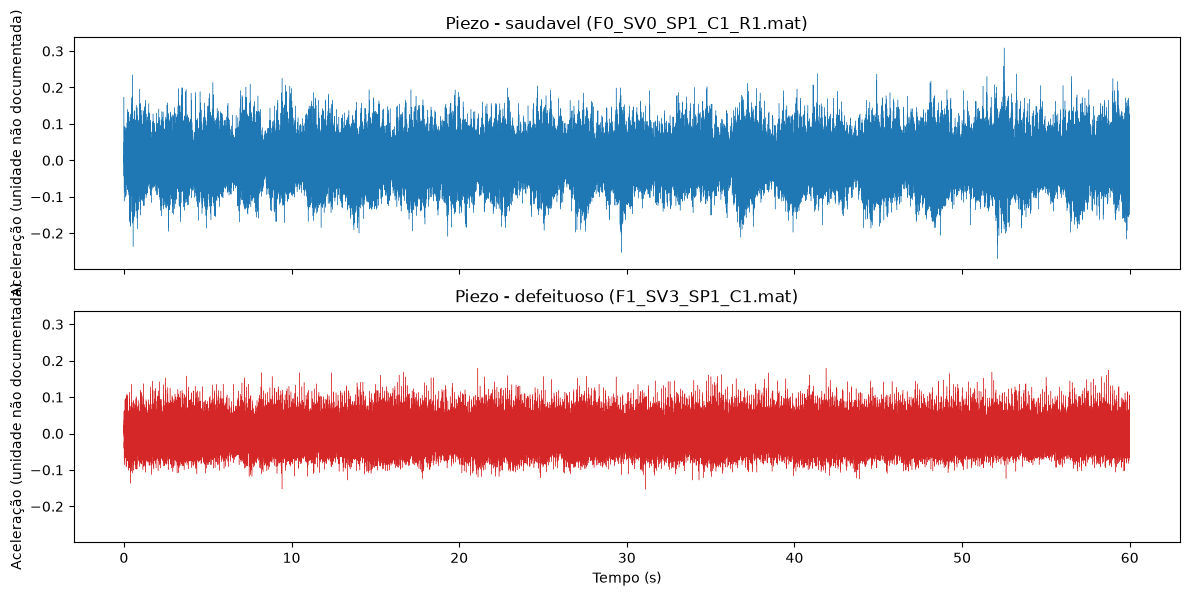

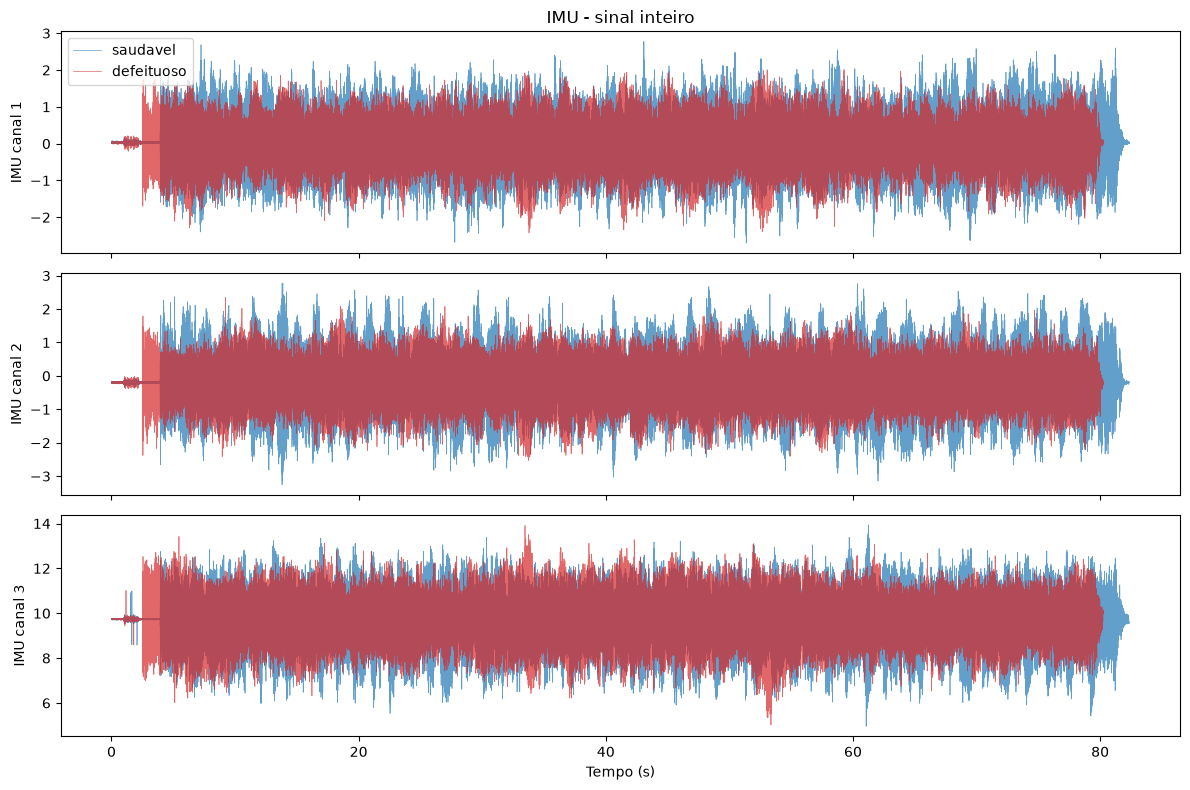

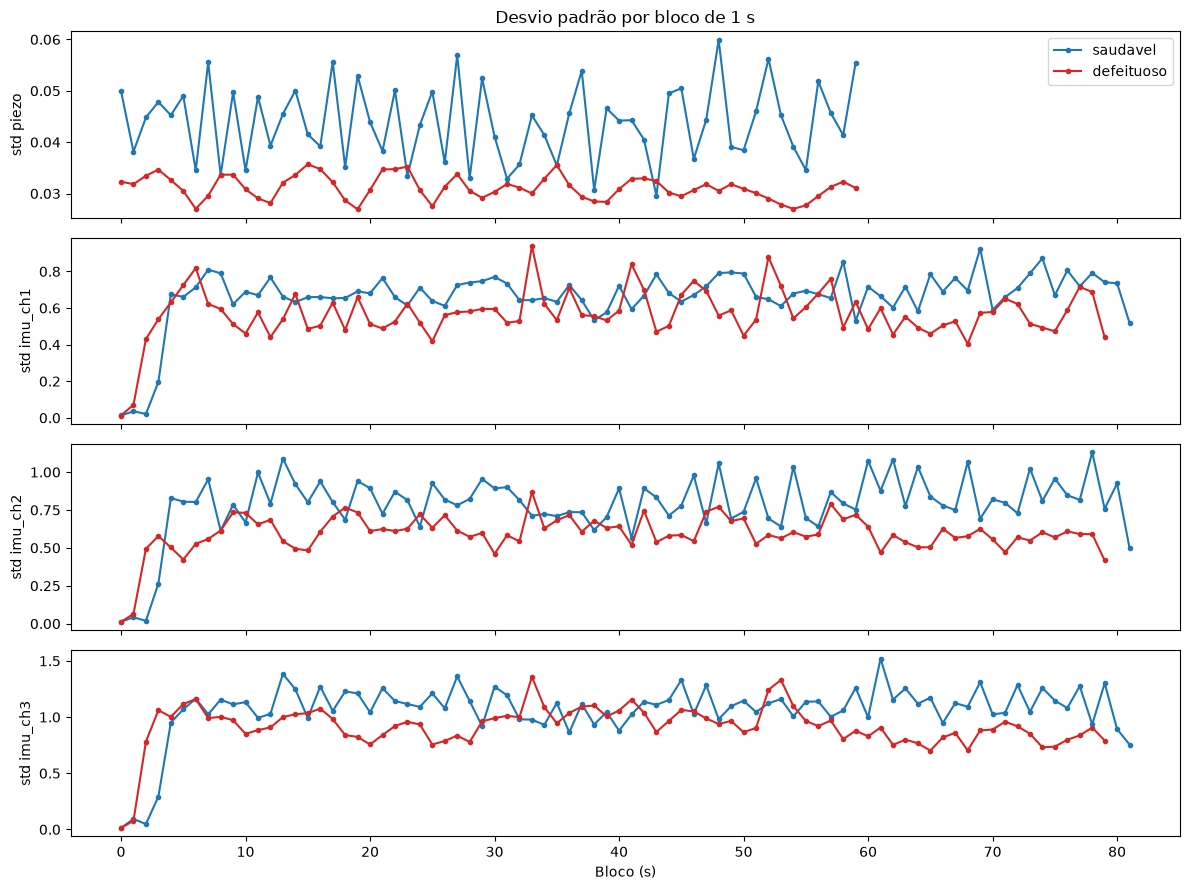

In [10]:
sinais = {cond: carregar(nome) for cond, nome in ARQ.items()}

linhas = []
for cond, (imu_s, acc_s) in sinais.items():
    for i in range(imu_s.Vib_Data.shape[0]):
        linhas.append({"cond": cond, "canal": f"imu_ch{i + 1}", **estat(imu_s.Vib_Data[i])})
    linhas.append({"cond": cond, "canal": "piezo", **estat(acc_s.Vib_Data)})

tab = pd.DataFrame(linhas).set_index(["canal", "cond"]).sort_index()
print(tab.round(4).to_string())

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (cond, (imu_s, acc_s)) in zip(axs, sinais.items()):
    ax.plot(acc_s.t, acc_s.Vib_Data, lw=0.3, color=CORES[cond])
    ax.set_title(f"Piezo - {cond} ({ARQ[cond]})")
    ax.set_ylabel("Aceleração (unidade não documentada)")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for i, ax in enumerate(axs):
    for cond, (imu_s, acc_s) in sinais.items():
        ax.plot(imu_s.t, imu_s.Vib_Data[i], lw=0.5, color=CORES[cond], alpha=0.7, label=cond)
    ax.set_ylabel(f"IMU canal {i + 1}")
axs[0].legend()
axs[0].set_title("IMU - sinal inteiro")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

series = [("piezo", lambda s: s[1].t, lambda s: s[1].Vib_Data)]
for i in range(3):
    series.append((f"imu_ch{i + 1}", lambda s: s[0].t, lambda s, i=i: s[0].Vib_Data[i]))

fig, axs = plt.subplots(len(series), 1, figsize=(12, 9), sharex=True)
for ax, (nome, get_t, get_x) in zip(axs, series):
    for cond, s in sinais.items():
        ax.plot(std_por_bloco(get_t(s), get_x(s)), color=CORES[cond], marker=".", label=cond)
    ax.set_ylabel(f"std {nome}")
axs[0].legend()
axs[0].set_title("Desvio padrão por bloco de 1 s")
axs[-1].set_xlabel("Bloco (s)")
plt.tight_layout()
plt.show()

In [11]:
N = 20000
chk = []
for _, r in sel.iterrows():
    x = ler_acc(r["arquivo"])
    k = len(x) // N
    s = x[:k * N].reshape(k, N).std(axis=1)
    chk.append({
        "arquivo": r["arquivo"], "nan": int(np.isnan(x).sum()),
        "pct_max": 100 * np.mean(x == x.max()), "pct_min": 100 * np.mean(x == x.min()),
        "std_min": s.min(), "std_max": s.max(), "n_jan": k,
    })
chk = pd.DataFrame(chk)
chk["razao"] = chk["std_max"] / chk["std_min"]
print(chk[["nan", "pct_max", "pct_min", "razao", "n_jan"]].describe().round(4).to_string())
print(chk.sort_values("razao", ascending=False).head(10).to_string(index=False))

        nan  pct_max  pct_min    razao    n_jan
count  99.0  99.0000  99.0000  99.0000  99.0000
mean    0.0   0.0003   0.0003   1.3271  23.9394
std     0.0   0.0002   0.0002   0.2035   9.2381
min     0.0   0.0002   0.0002   1.0275  10.0000
25%     0.0   0.0002   0.0002   1.1530  10.0000
50%     0.0   0.0002   0.0002   1.3105  30.0000
75%     0.0   0.0005   0.0005   1.4889  30.0000
max     0.0   0.0010   0.0010   1.9496  30.0000
             arquivo  nan  pct_max  pct_min  std_min  std_max  n_jan    razao
   F1_SV1_SP1_C2.mat    0 0.000167 0.000167 0.032521 0.063402     30 1.949603
   F3_SV3_SP2_C2.mat    0 0.000167 0.000167 0.074287 0.139003     30 1.871164
F0_SV0_SP1_C3_R2.mat    0 0.000167 0.000167 0.013694 0.023628     30 1.725432
   F3_SV2_SP1_C2.mat    0 0.000167 0.000167 0.024316 0.041079     30 1.689368
   F3_SV2_SP1_C1.mat    0 0.000167 0.000167 0.023049 0.038240     30 1.659049
   F3_SV1_SP2_C2.mat    0 0.000167 0.000167 0.073855 0.122203     30 1.654639
   F3_SV2_SP3_C2.mat  

In [12]:
jan = sel[["arquivo", "id", "rotulo", "F", "SV", "SP", "C"]].copy()
jan["n_jan"] = (sel["n_acc_sig"] // N).astype(int).values
jan = jan.loc[jan.index.repeat(jan["n_jan"])].copy()
jan["jan"] = jan.groupby("arquivo").cumcount()
jan["ini"] = jan["jan"] * N
jan["fim"] = jan["ini"] + N
jan = jan.reset_index(drop=True)
print(len(jan))
print(jan.groupby("rotulo").size())
jan.to_csv("../data/processed/janelas.csv", index=False)

2370
rotulo
defeituoso    1890
saudavel       480
dtype: int64
